# Supervised Learning - Random Forest

Random Forest fraud classifier using the same out-of-time validation and test structure as `supervised.ipynb`.

Input: `data/processed/fraudTrain_features.csv`, `data/processed/fraudTest_features.csv`

The model is selected by validation PR-AUC, the fraud threshold is selected by validation F1, and the final model is evaluated on the later test period.


In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import average_precision_score, classification_report, confusion_matrix, precision_recall_curve, roc_auc_score, roc_curve

pd.set_option("display.max_columns", None)
%matplotlib inline
DATA_DIR = Path("data/processed")
BLUE, ORANGE, RED = "#2a78d6", "#eb6834", "#e34948"
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e6e5e1"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRID, "figure.dpi": 110})


## 1. Load data

In [2]:
train = pd.read_csv(DATA_DIR / "fraudTrain_features.csv")
test = pd.read_csv(DATA_DIR / "fraudTest_features.csv")

X_train_full = train.drop(columns=["is_fraud"]).astype("float32")
y_train_full = train["is_fraud"]
X_test = test.drop(columns=["is_fraud"]).astype("float32")
y_test = test["is_fraud"]

print("train:", X_train_full.shape, f"fraud rate {y_train_full.mean():.3%}")
print("test: ", X_test.shape, f"fraud rate {y_test.mean():.3%}")

train: (1296675, 83) fraud rate 0.579%
test:  (555719, 83) fraud rate 0.386%


## 2. Out-of-time validation split

The data is split three ways:

| Split | Rows | Period | Used for |
|---|---|---|---|
| **Train (fit)** | first 80% of `fraudTrain` | Jan 2019 – Mar 2020 | fitting model coefficients |
| **Validation** | last 20% of `fraudTrain` | Mar 2020 – Jun 2020 | choosing `C` and the decision threshold |
| **Test** | all of `fraudTest` | Jun 2020 – Dec 2020 | final evaluation, used once |

The training rows are in time order, so taking the last 20% as validation gives an **out-of-time** split, the same way the test set relates to the training set. A random split would let the model see transactions from the same days it is validated on, which overstates performance on future data.

In [3]:
cut = int(len(X_train_full) * 0.8)
X_tr, y_tr = X_train_full.iloc[:cut], y_train_full.iloc[:cut]
X_val, y_val = X_train_full.iloc[cut:], y_train_full.iloc[cut:]

pd.DataFrame({
    "rows": [len(X_tr), len(X_val), len(X_test)],
    "fraud": [y_tr.sum(), y_val.sum(), y_test.sum()],
    "fraud rate": [f"{y_tr.mean():.3%}", f"{y_val.mean():.3%}", f"{y_test.mean():.3%}"],
}, index=["train (fit)", "validation", "test"])

,rows,fraud,fraud rate
train (fit),1037340,5968,0.575%
validation,259335,1538,0.593%
test,555719,2145,0.386%


## 3. Random Forest pipeline

Random Forests do not require feature scaling. `class_weight="balanced_subsample"` compensates for the rare fraud class in each bootstrap sample. The threshold is tuned separately because the probability scores are used primarily for ranking.


In [4]:
def make_model(max_depth=None, min_samples_leaf=2):
    # One worker avoids duplicating the 1.3M-row training matrix in memory.
    return RandomForestClassifier(n_estimators=100, max_depth=max_depth, min_samples_leaf=min_samples_leaf, max_features="sqrt", class_weight="balanced_subsample", n_jobs=1, random_state=42)


## 4. Validation: choosing tree settings and the threshold

### 4a. Tree hyperparameters

Each candidate is fitted on the first 80% and scored on the out-of-time validation rows by PR-AUC. The test set remains untouched.


In [5]:
candidates = [(12, 2), (20, 2), (None, 2)]
results, models = [], {}
for max_depth, min_leaf in candidates:
    key = (max_depth, min_leaf)
    models[key] = make_model(max_depth, min_leaf).fit(X_tr, y_tr)
    proba = models[key].predict_proba(X_val)[:, 1]
    results.append({"max_depth": max_depth, "min_samples_leaf": min_leaf, "val PR-AUC": average_precision_score(y_val, proba), "val ROC-AUC": roc_auc_score(y_val, proba)})
rf_results = pd.DataFrame(results)
best_index = rf_results["val PR-AUC"].idxmax()
best_key = candidates[best_index]
model = models[best_key]
val_proba = model.predict_proba(X_val)[:, 1]
print(f"Best settings: max_depth={best_key[0]}, min_samples_leaf={best_key[1]}")
print(f"Validation PR-AUC: {average_precision_score(y_val, val_proba):.4f} (random = {y_val.mean():.4f})")
print(f"Validation ROC-AUC: {roc_auc_score(y_val, val_proba):.4f}")
rf_results.round(4)


Best settings: max_depth=None, min_samples_leaf=2
Validation PR-AUC: 0.8952 (random = 0.0059)
Validation ROC-AUC: 0.9914


,max_depth,min_samples_leaf,val PR-AUC,val ROC-AUC
0,12.0,2,0.8239,0.9929
1,20.0,2,0.8619,0.9943
2,NaN,2,0.8952,0.9914


### 4b. Decision threshold

The threshold that maximises fraud F1 on validation data is fixed before test evaluation.



Best-F1 threshold: 0.4478

              precision    recall  f1-score   support

  legitimate      0.999     0.999     0.999    257797
       fraud      0.897     0.800     0.846      1538

    accuracy                          0.998    259335
   macro avg      0.948     0.900     0.923    259335
weighted avg      0.998     0.998     0.998    259335



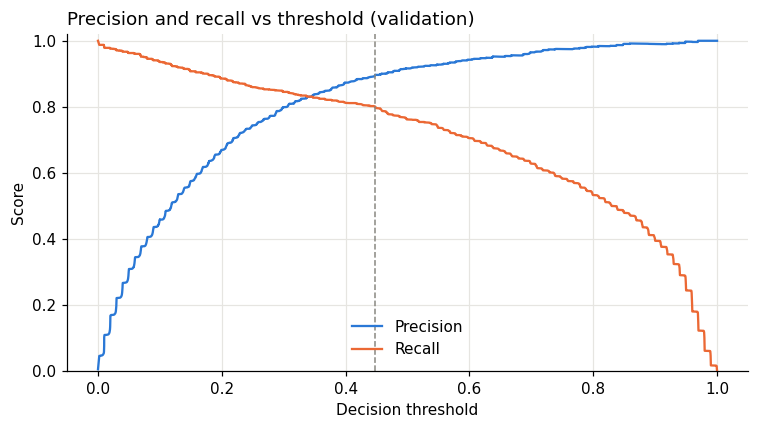

In [6]:
precision, recall, thresholds = precision_recall_curve(y_val, val_proba)
f1 = 2 * precision[:-1] * recall[:-1] / np.clip(precision[:-1] + recall[:-1], 1e-12, None)
threshold = thresholds[np.argmax(f1)]
print(f"Best-F1 threshold: {threshold:.4f}\n")
print(classification_report(y_val, (val_proba >= threshold).astype(int), target_names=["legitimate", "fraud"], digits=3))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(thresholds, precision[:-1], color=BLUE, label="Precision")
ax.plot(thresholds, recall[:-1], color=ORANGE, label="Recall")
ax.axvline(threshold, color=MUTED, linestyle="--", linewidth=1)
ax.set(xlabel="Decision threshold", ylabel="Score", ylim=(0, 1.02))
ax.set_title("Precision and recall vs threshold (validation)", loc="left")
ax.legend(frameon=False); plt.tight_layout(); plt.show()

The default 0.5 threshold is poorly suited here: because of the class weighting it flags far too many legitimate transactions. The threshold that maximises **F1** (the balance of precision and recall) on the validation set is chosen instead. If the business cost of a missed fraud is much higher than a false alarm, a lower threshold (higher recall) could be picked from the same curve.

## 5. Final model on the test set

The selected settings and threshold are fixed. The model is refit on all of `fraudTrain` and evaluated once on `fraudTest`.


In [8]:
final_model = make_model(*best_key).fit(X_train_full, y_train_full)

test_proba = final_model.predict_proba(X_test)[:, 1]

print(
    f"Test PR-AUC: {average_precision_score(y_test, test_proba):.4f} "
    f"(random = {y_test.mean():.4f})"
)
print(f"Test ROC-AUC: {roc_auc_score(y_test, test_proba):.4f}")

for name, t in [
    ("default 0.5", 0.5),
    (f"tuned {threshold:.2f}", threshold),
]:
    print(f"\n=== Threshold: {name} ===")
    print(
        classification_report(
            y_test,
            (test_proba >= t).astype(int),
            target_names=["legitimate", "fraud"],
            digits=3,
            zero_division=0,
        )
    )

Test PR-AUC: 0.8598 (random = 0.0039)
Test ROC-AUC: 0.9884

=== Threshold: default 0.5 ===
              precision    recall  f1-score   support

  legitimate      0.999     1.000     0.999    553574
       fraud      0.893     0.749     0.815      2145

    accuracy                          0.999    555719
   macro avg      0.946     0.874     0.907    555719
weighted avg      0.999     0.999     0.999    555719


=== Threshold: tuned 0.45 ===
              precision    recall  f1-score   support

  legitimate      0.999     1.000     0.999    553574
       fraud      0.866     0.772     0.816      2145

    accuracy                          0.999    555719
   macro avg      0.933     0.886     0.908    555719
weighted avg      0.999     0.999     0.999    555719



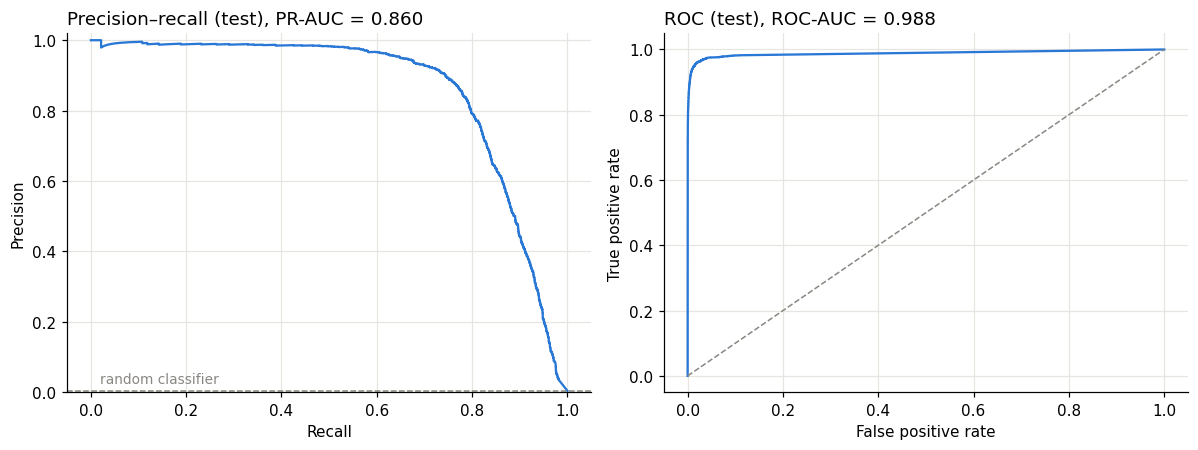

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))

p, r, _ = precision_recall_curve(y_test, test_proba)
axes[0].plot(r[:-1], p[:-1], color=BLUE)  # drop sklearn's artificial (recall=0, precision=1) end point
axes[0].axhline(y_test.mean(), color=MUTED, linestyle="--", linewidth=1)
axes[0].annotate("random classifier", (0.02, y_test.mean()), xytext=(0, 5),
                 textcoords="offset points", color=MUTED, fontsize=9)
axes[0].set_xlabel("Recall")
axes[0].set_ylabel("Precision")
axes[0].set_ylim(0, 1.02)
axes[0].set_title(f"Precision–recall (test), PR-AUC = {average_precision_score(y_test, test_proba):.3f}", loc="left")

fpr, tpr, _ = roc_curve(y_test, test_proba)
axes[1].plot(fpr, tpr, color=BLUE)
axes[1].plot([0, 1], [0, 1], color=MUTED, linestyle="--", linewidth=1)
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate")
axes[1].set_title(f"ROC (test), ROC-AUC = {roc_auc_score(y_test, test_proba):.3f}", loc="left")

plt.tight_layout()
plt.show()

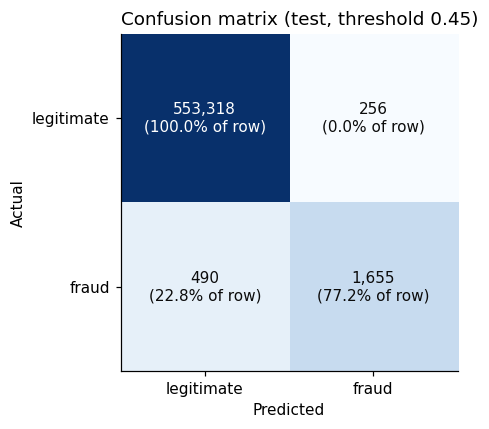

,predicted legitimate,predicted fraud
actual legitimate,553318,256
actual fraud,490,1655


In [10]:
cm = confusion_matrix(y_test, (test_proba >= threshold).astype(int))
labels = ["legitimate", "fraud"]

fig, ax = plt.subplots(figsize=(4.8, 4))
ax.imshow(np.log10(cm + 1), cmap="Blues")
ax.grid(False)
for i in range(2):
    for j in range(2):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, f"{cm[i, j]:,}\n({share:.1%} of row)", ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 10 else INK)
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title(f"Confusion matrix (test, threshold {threshold:.2f})", loc="left")
plt.tight_layout()
plt.show()

pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"predicted {l}" for l in labels])

## 6. Feature importance

Random Forest feature importance measures the average impurity reduction contributed by each feature. These are predictive associations, not causal effects.


In [11]:
importances = pd.DataFrame({"feature": X_train_full.columns, "importance": final_model.feature_importances_}).sort_values("importance", ascending=False).reset_index(drop=True)
importances.head(20).round(5)


,feature,importance
0,log_amt,0.23421
1,amt,0.21266
2,amt_is_large,0.15455
3,hour_cos,0.08920
4,hour,0.07010
5,hour_sin,0.03417
6,age,0.01788
7,city_pop,0.01281
8,category_shopping_net,0.01270
9,is_night,0.01185


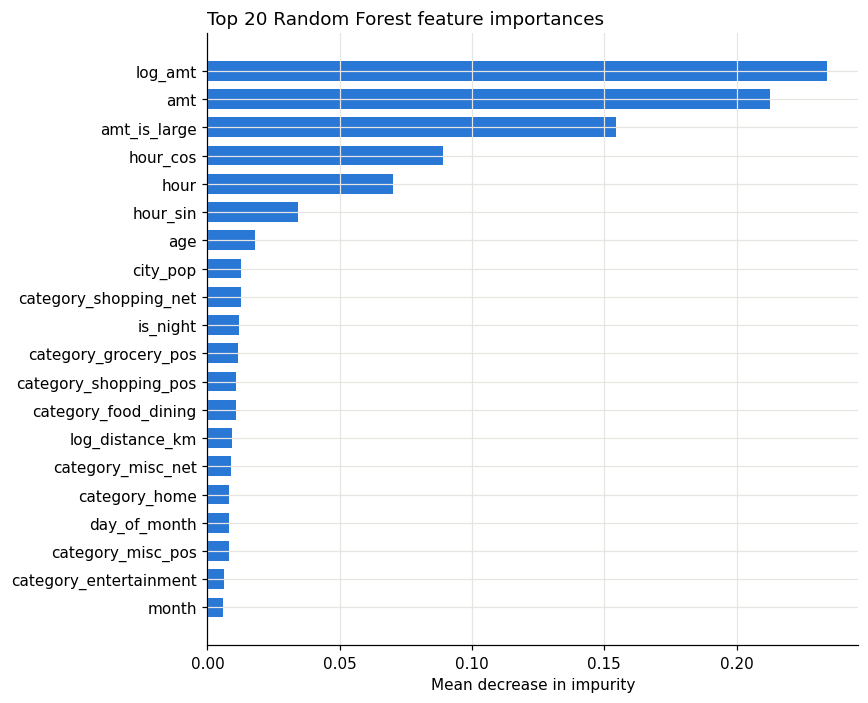

In [12]:
top = importances.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(top["feature"], top["importance"], color=BLUE, height=0.7)
ax.set_xlabel("Mean decrease in impurity")
ax.set_title("Top 20 Random Forest feature importances", loc="left")
plt.tight_layout(); plt.show()


## 7. Results summary

Compare validation and test PR-AUC, ROC-AUC, and fraud precision/recall/F1 with the logistic regression notebook. Random Forest learns non-linear interactions such as amount, category, and time of day automatically.
